# Expected limits with and without the corrections and systematic uncertainties

The limits use the ABCD method with a shape fit in $m_{LJLJ}$: in each channel, region A
(the signal region) is predicted bin by bin from the control regions B, C and D through a
transfer factor, as a `RooParametricHist` model (`sidm/scripts/abcd_workspace.py`,
`global_tf`), and the signal enters all four regions. This notebook builds those datacards
twice from the same campaign, runs Combine on both, and compares the expected limits:

* **without corrections or systematics**: signal and background weighted by the genWeight
  alone (the `uncorrected` category of the `syst` axis), and no systematic uncertainty on
  the signal;
* **with corrections and systematics**: the standard corrections applied (the `nominal`
  category) and every entry of `systematics.yaml` on the signal.

Both keep the statistical uncertainty of the simulated signal and the free background
parameters of the ABCD model. The limits are drawn as Brazil bands with the model cross
section, against the bound state mass and against $L_{xy}$. The notebook ends with the
nuisance pulls of one signal point.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

**Simulation only.** Signal and background are simulation, data_obs is simulation, and
Combine runs blinded (`--run blind`), so every limit is an expected one.

**This notebook follows `systematics.yaml`.** Adding a systematic means adding an entry
there and rerunning this notebook; nothing here needs to change.

**Everything stays on EOS.** The inputs are read and the outputs (shapes, systematics,
datacards, workspaces, limits, figures, pulls) written through xrootd, so the notebook runs the same
at the LPC and on CoffeaCasa, where EOS is not mounted. Combine needs local files, so it works
in a temporary directory, which is copied to EOS and removed at the end. Combine is taken from
the `PATH` if it is there (e.g. a conda installation), otherwise from the CMSSW release that
`run_combine_limits.py` uses at the LPC.

Inputs: the merged outputs of the `systematics_v2` campaign
(`condor/campaign_configs/systematics_v2.yaml`): the `abcd6d_*` histograms of the
`SR_2mu2e` and `SR_4mu` channels with every weight variation on the `syst` axis. Region A
is that of the working points, `systematics_study.WORKING_POINTS`. Run that campaign before
this notebook (`condor/README.md`, section 23); until its merged outputs exist, the first
code cell stops and says so.

In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
dt = sysstudy.dt
rcl = sysstudy.rcl   # sidm/scripts/run_combine_limits.py

CAMPAIGN = "systematics_v2"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)   # signal and background share one merged directory
OUTPUT_DIR = f"{INPUT_DIR}_limits"                  # shapes, systematics, cards, limits and pulls
if not sysstudy.list_coffea(INPUT_DIR):
    raise FileNotFoundError(
        f"No merged outputs in {INPUT_DIR} yet. Run the {CAMPAIGN} campaign first, from the "
        f"repository root: python condor/campaign.py {CAMPAIGN} submit, then status and "
        f"retry --submit until every chunk is done, then merge (condor/README.md, section 23).")
WORK = Path(tempfile.mkdtemp(prefix=f"limits_{CAMPAIGN}_"))   # removed at the end
REGISTRY = sysstudy.load_registry()
PULLS_POINT = ("SR_2mu2e", "2Mu2E_500GeV_1p2GeV_1p9mm")   # the point whose pulls are shown

# Combine from the PATH, else the CMSSW release run_combine_limits.py dispatches to at the LPC
COMBINE = sysstudy.find_combine()
print("inputs: ", INPUT_DIR)
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(f"{name} ({next(iter(entry))})" for name, entry in REGISTRY.items()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV (flat), CMS_pileup (syst), CMS_l1_prefiring (flat), CMS_jet_energy (variant)


## 1. Inputs

One pass over the merged outputs: the region shapes of every sample at the working points,
with and without the corrections, and, for every signal point, the change of its yield in
each region under each systematic (`systematics_study.abcd_inputs`). Both are written to
EOS, under `inputs/<set>/`, as the handover to Combine.

In [2]:
# The two sets of limits: the event weights (a category of the syst axis) and the
# systematics.yaml entries on the signal
SETS = {
    "without": {"weights": "uncorrected", "systematics": [], "label": "no corrections or systematics"},
    "with": {"weights": "nominal", "systematics": list(REGISTRY), "label": "with corrections and systematics"},
}
inputs, kappas = sysstudy.abcd_inputs(INPUT_DIR, REGISTRY, weights=[s["weights"] for s in SETS.values()])
background, signal = inputs["nominal"]
# lifetimes are ranked on the full grid, so the limit grid is taken from it
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(signal)
print(f"{len(background)} background samples, {len(signal)} signal points ({len(LIMIT)} on the limit grid)")

print(f"\n{'weights':12s} {'channel':9s} {'A':>9s} {'B':>9s} {'C':>9s} {'D':>9s} {'B*C/D':>9s}"
      "   simulated background at the working points")
for weights, (samples, _) in inputs.items():
    grouped = sysstudy.st.group_shapes(samples)
    for channel in sysstudy.WORKING_POINTS:
        totals = [sum(float(group[channel][r].sumw.sum()) for group in grouped.values() if channel in group)
                  for r in range(4)]
        predicted = totals[1] * totals[2] / totals[3] if totals[3] > 0 else float("nan")
        print(f"{weights:12s} {channel:9s} " + " ".join(f"{t:9.3f}" for t in totals) + f" {predicted:9.3f}")

payloads = {}
for name, spec in SETS.items():
    payloads[name] = sysstudy.write_payloads(WORK / "inputs" / name, *inputs[spec["weights"]],
                                             weights=spec["weights"])
    (WORK / "inputs" / name / "systematics.json").write_text(
        json.dumps({"sources": spec["systematics"], "kappas": kappas, "registry": REGISTRY}))
sysstudy.upload(WORK / "inputs", f"{OUTPUT_DIR}/inputs")
print(f"\nshapes and systematics written to {OUTPUT_DIR}/inputs")

18 background samples, 180 signal points (96 on the limit grid)

weights      channel           A         B         C         D     B*C/D   simulated background at the working points
nominal      SR_2mu2e     25.209   144.107    80.682    25.297   459.604
nominal      SR_4mu       20.882    26.326     0.039     2.751     0.377
uncorrected  SR_2mu2e     24.924   149.212    87.034    27.272   476.192
uncorrected  SR_4mu       21.105    27.095     0.038     2.745     0.372

shapes and systematics written to root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits/inputs


**Interpretation (run of 2026-11-14: `systematics_v2`, four systematics, 4mu at most 3 pixel hits).**
The ABCD prediction for the simulated background in region A is B·C/D: 460 events for 2mu2e
(476 without the corrections) and 0.38 for 4mu (0.37 without). The generator-filter efficiency
that `systematics_v2` adds acts on the signal only, so these are also the numbers of
`systematics_v1`.

* In 2mu2e the prediction is far above the 25 events that region A holds in the simulation.
  B and C come from a few heavily weighted QCD events (about 1.5 effective events each), so
  B·C/D has a large statistical uncertainty and is not a usable background estimate.
* In 4mu, region C is nearly empty (0.039 events), so the prediction is 0.38 events and the
  4mu limits are close to zero-background limits. Region A holds 20.9 events, 19.3 of them
  Drell-Yan (about 6 effective events, all below 300 GeV in $m_{LJLJ}$). Drell-Yan muon pairs
  are isolated and back-to-back, so they land in A and not in B, C or D; the prediction from
  those regions does not contain them, and neither do the limits, which use the prediction.
  With the earlier cut of 2 pixel hits, A held 3.6 events, from one Drell-Yan event.
* The corrections move the background by a few percent, far less than these limitations.

**For the analysis:** the simulation-only limits test the fit machinery and the effect of the
signal systematics; they are not sensitivity estimates. Those need B, C and D from data, and the
4mu prediction is only defined where C and D have events (notebook 05).

## 2. The corrections and the systematic uncertainties of the signal

In region A, over the signal points of the limit grid: the change of the signal yield from
the corrections (with over without), and the size of each systematic: the relative change
for a symmetric one, half the difference of up and down for an asymmetric one.

In [3]:
print(f"{'channel':9s} {'median':>8s} {'min':>8s} {'max':>8s}   signal in region A, with / without the corrections")
for channel, final_state in (("SR_2mu2e", "2Mu2E"), ("SR_4mu", "4Mu")):
    ratios = []
    for s in LIMIT:
        if s.startswith(final_state + "_"):
            corrected, uncorrected = (float(inputs[w][1][s][channel][0].sumw.sum()) for w in ("nominal", "uncorrected"))
            if uncorrected > 0:
                ratios.append(corrected / uncorrected)
    if ratios:
        print(f"{channel:9s} {np.median(ratios):8.3f} {min(ratios):8.3f} {max(ratios):8.3f}")
print()
size = sysstudy.kappa_size

print(f"{'nuisance':20s} {'channel':9s} {'median (%)':>11s} {'max (%)':>9s}")
for name in REGISTRY:
    for channel, final_state in (("SR_2mu2e", "2Mu2E"), ("SR_4mu", "4Mu")):
        values = [100 * size(kappas[s][name]["A"]) for s in LIMIT if s.startswith(final_state + "_")]
        if values:
            print(f"{name:20s} {channel:9s} {np.median(values):11.2f} {max(values):9.2f}")

channel     median      min      max   signal in region A, with / without the corrections
SR_2mu2e     0.948    0.936    0.983
SR_4mu       0.988    0.984    0.995

nuisance             channel    median (%)   max (%)
lumi_13TeV           SR_2mu2e         0.83      0.83
lumi_13TeV           SR_4mu           0.83      0.83
CMS_pileup           SR_2mu2e         0.42      1.48
CMS_pileup           SR_4mu           0.16      0.64
CMS_l1_prefiring     SR_2mu2e         1.00      1.00
CMS_l1_prefiring     SR_4mu           1.00      1.00
CMS_jet_energy       SR_2mu2e         0.53      2.24
CMS_jet_energy       SR_4mu           0.14      0.57


**Interpretation.** The corrections lower the signal in region A by 5.2% for 2Mu2E (1.7 to
6.4%) and by 1.2% for 4Mu (0.5 to 1.6%); the corrections README breaks this down by correction.
The four systematics are 1% or less at a typical point: luminosity 0.83% and prefiring 1% at
every point, pileup and jet energy a few tenths of a percent, at most 1.5% and 2.2% (2Mu2E).

**For the analysis:** the corrections change the signal yield by more than the four
systematics together, so they belong in every limit input. The systematics are small next to
the statistical uncertainty of the simulated signal at many points (notebook 04) and next to
the lepton-jet reconstruction efficiency, which is still to be measured.

## 3. Datacards and limits

Each set has its own shapes, made with its event weights, and its own log-normal rows on
the signal (`abcd_workspace.py --signal-systematics`; none in the set without). The
workspaces need ROOT and Combine, so they are built with Combine's environment, which
`run_combine_limits.py` also uses for the limits. The limits are computed to a relative
precision of $10^{-4}$, since the default of $5\times10^{-3}$ is as large as the effect of
the systematics. The cards, workspaces, limits and logs are copied to EOS, and the limits
are read back from there.

In [4]:
if COMBINE is None:
    raise RuntimeError(f"Combine is not available here: put `combine` on the PATH or set "
                       f"COMBINE_CMSSW_BASE. The shapes and systematics are on EOS, in {OUTPUT_DIR}/inputs.")
repo = Path(sidm_path)
for name, spec in SETS.items():
    cards = WORK / f"cards_{name}"
    for channel, payload in payloads[name].items():
        inner = (f"cd {repo} && python3 sidm/scripts/abcd_workspace.py --shapes {payload} --outdir {cards} "
                 f"--signal-systematics {WORK / 'inputs' / name / 'systematics.json'}")
        sysstudy.run_logged(rcl.in_combine_release(inner, COMBINE), WORK / f"workspace_{name}_{channel}.log")
    # a card that fails is listed in the log; the others still give limits
    log = WORK / f"limits_{name}.log"
    sysstudy.run_script("run_combine_limits.py", "--datacards", cards, "--pattern", "datacard_shape_*.txt",
                        "--outdir", WORK / f"limits_{name}", "-j", "8", "--extra=--rRelAcc 0.0001 --rAbsAcc 0.00001",
                        combine=COMBINE, log=log, check=False)
    print(f"{spec['label']}: {log.read_text().count('FAILED')} cards failed (see {log.name} in {OUTPUT_DIR})")
sysstudy.upload(WORK, OUTPUT_DIR)

# the limits, read back from EOS, on the limit grid
rows = {name: [r for r in pt.as_rows(f"{OUTPUT_DIR}/limits_{name}/limits.csv") if r["signal"] in LIMIT]
        for name in SETS}
print({SETS[name]["label"]: len(r) for name, r in rows.items()}, "expected limits on the limit grid, read from", OUTPUT_DIR)

no corrections or systematics: 0 cards failed (see limits_without.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits)


with corrections and systematics: 0 cards failed (see limits_with.log in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits)


{'no corrections or systematics': 96, 'with corrections and systematics': 96} expected limits on the limit grid, read from root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits


## 4. The limits

The expected 95% CL limits on the cross section on the limit grid (the signal is
normalised to 1 fb, so $r$ is the limit in fb). In every panel the set with corrections and
systematics is the Brazil band (green $\pm1\sigma$, yellow $\pm2\sigma$, black dashed
median), the set without them is drawn over it in blue (solid median, dotted band edges),
and the red line is the model cross section (`sidm/configs/cross_sections.yaml`), which
depends only on the bound state mass. The first grid of each final state shows the limits
against the bound state mass, one panel per dark photon mass and $L_{xy}$; the second
against $L_{xy}$, one panel per dark photon mass and bound state mass
(`plot_tools.brazil_grid`). The figures are written to EOS, under `figures/`, as PDF and PNG.

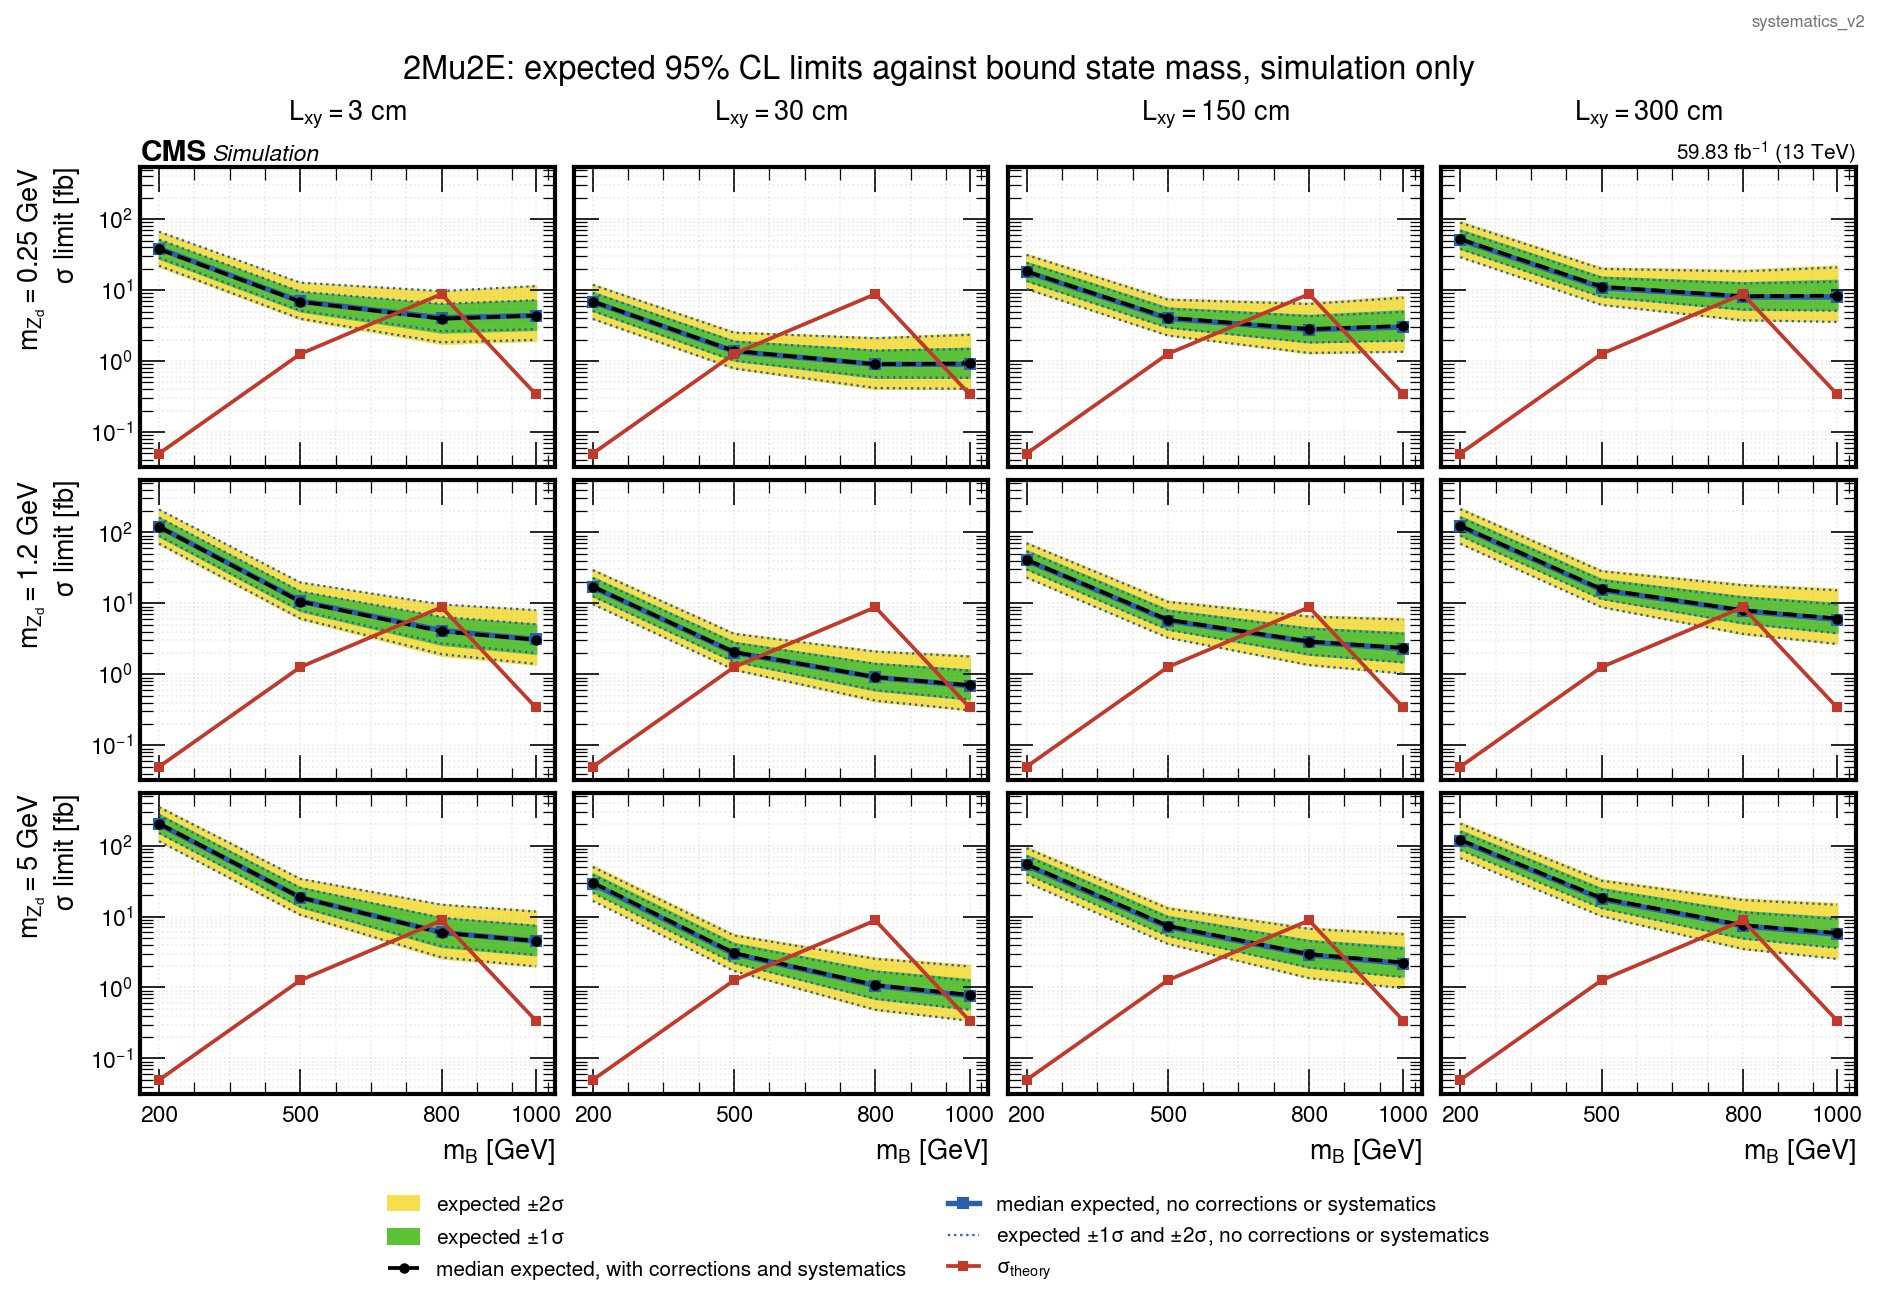

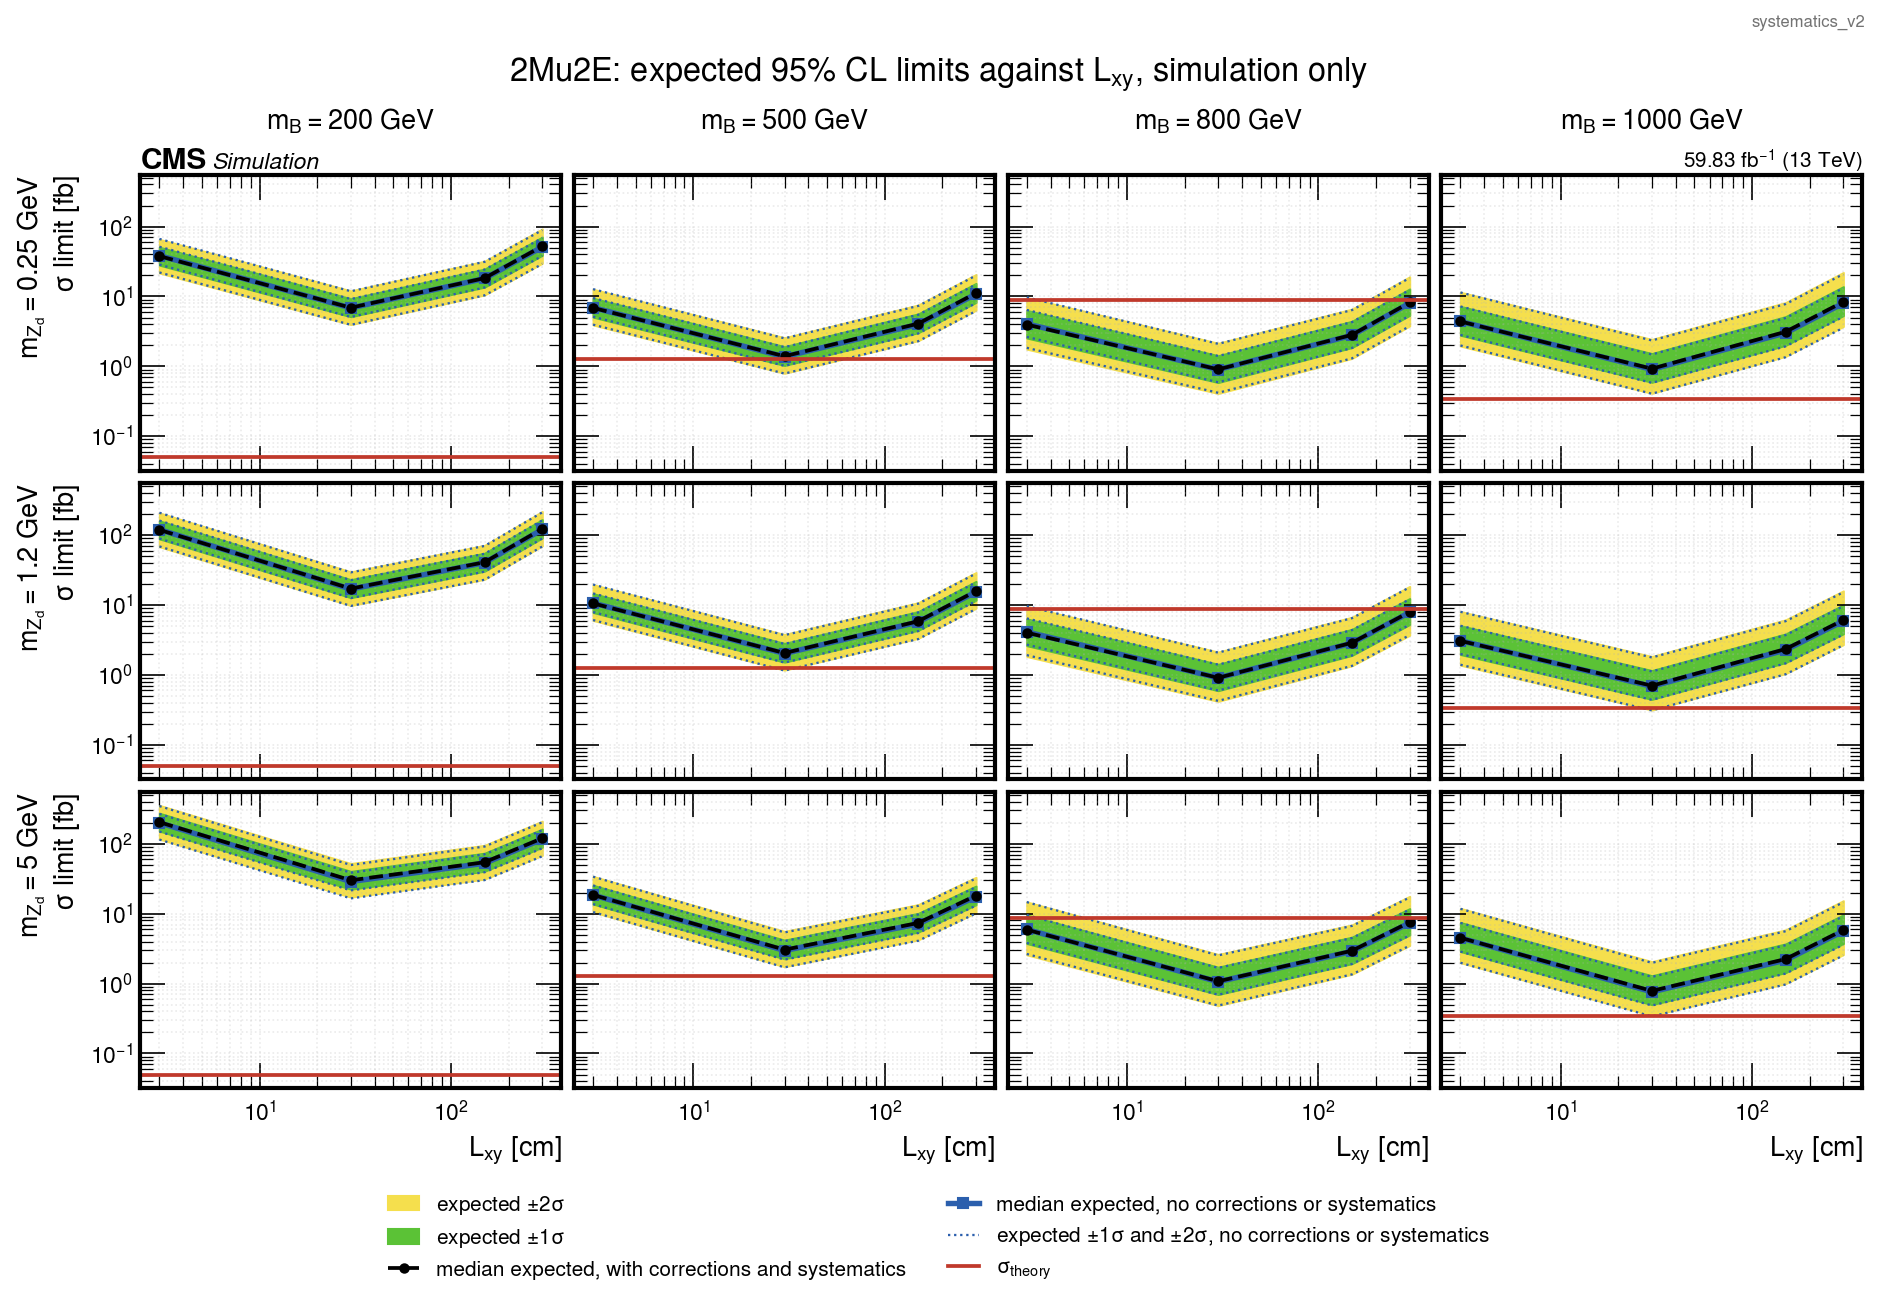

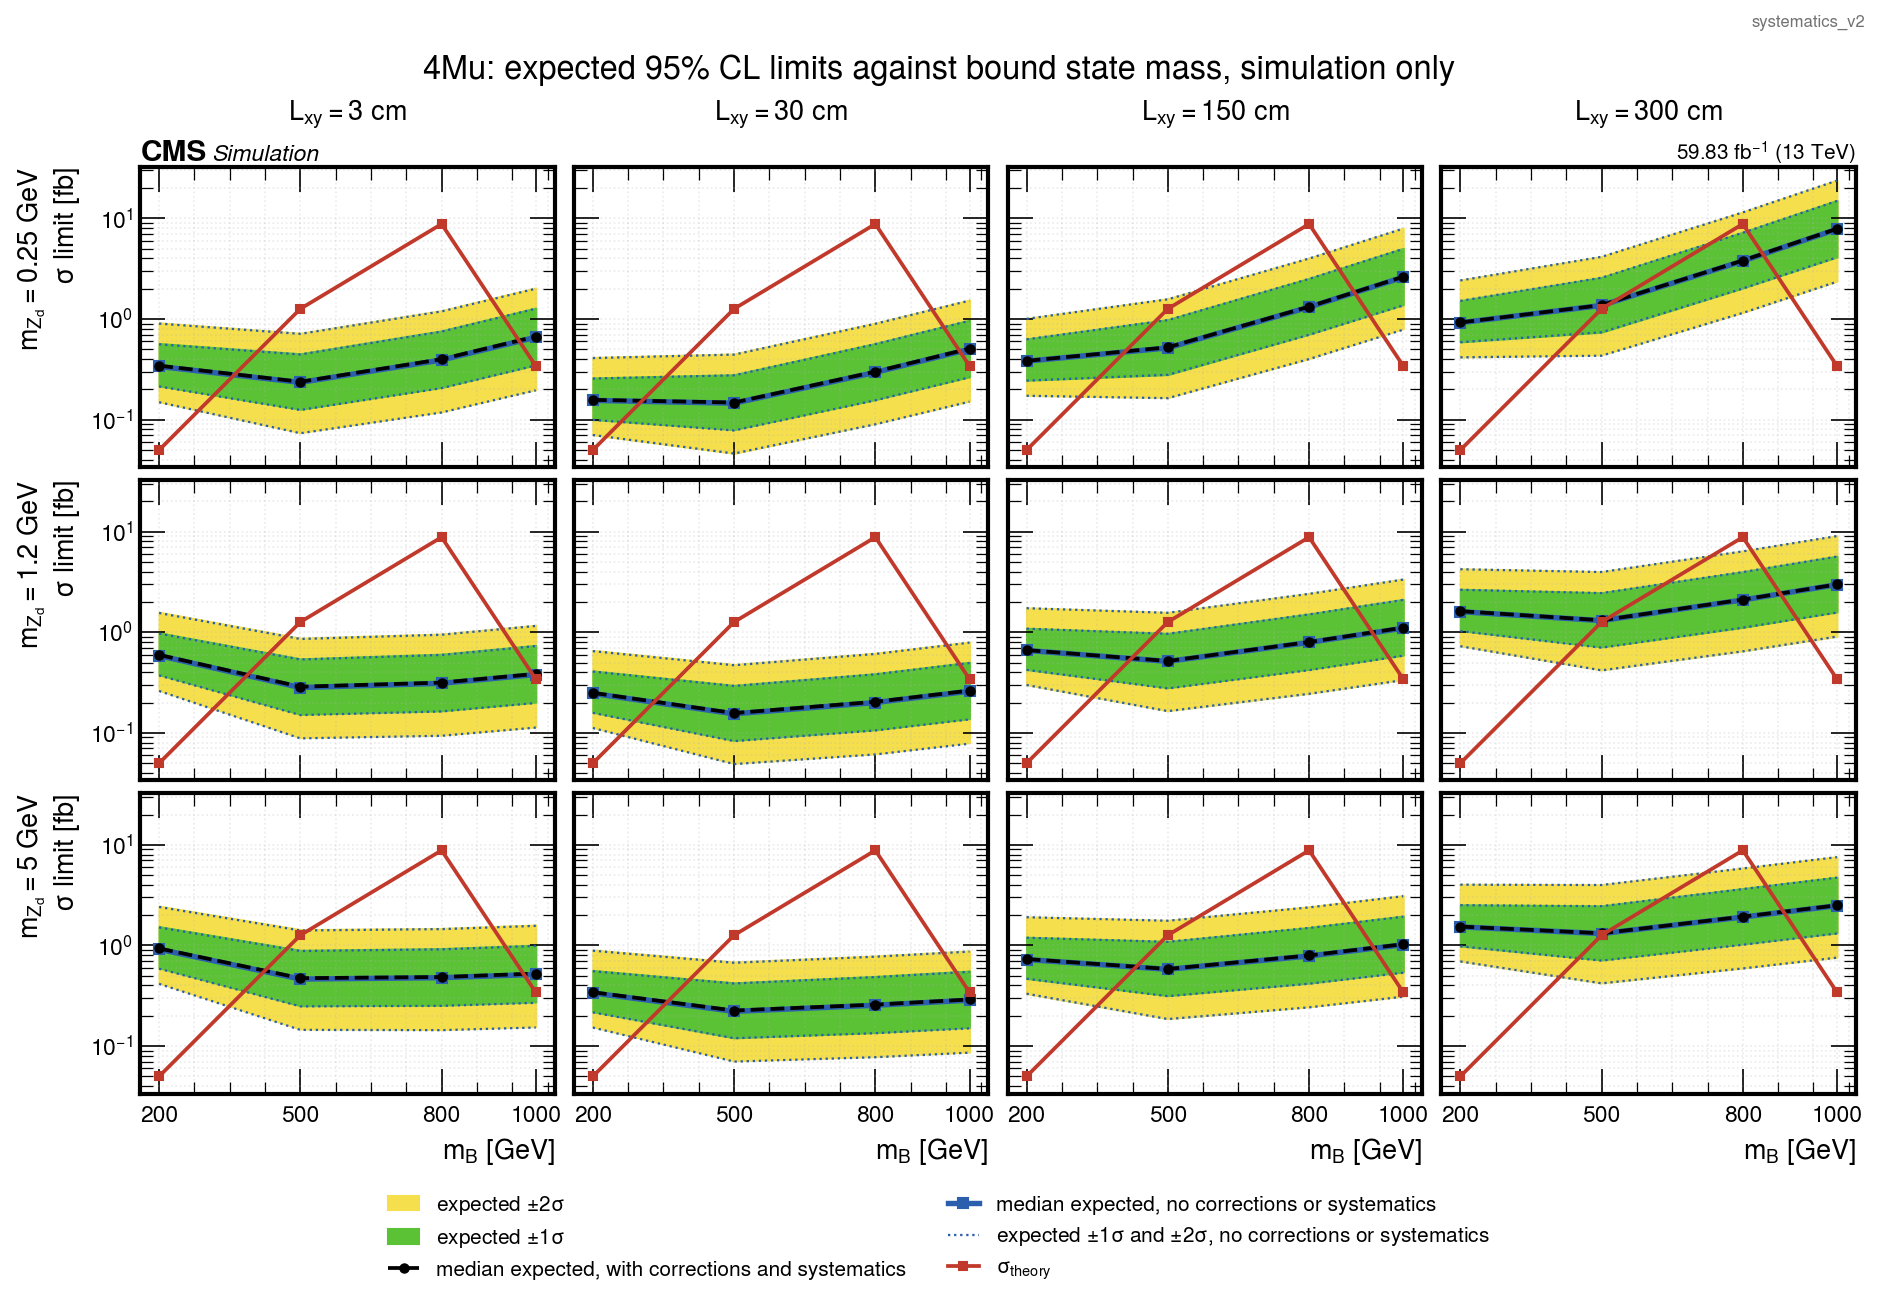

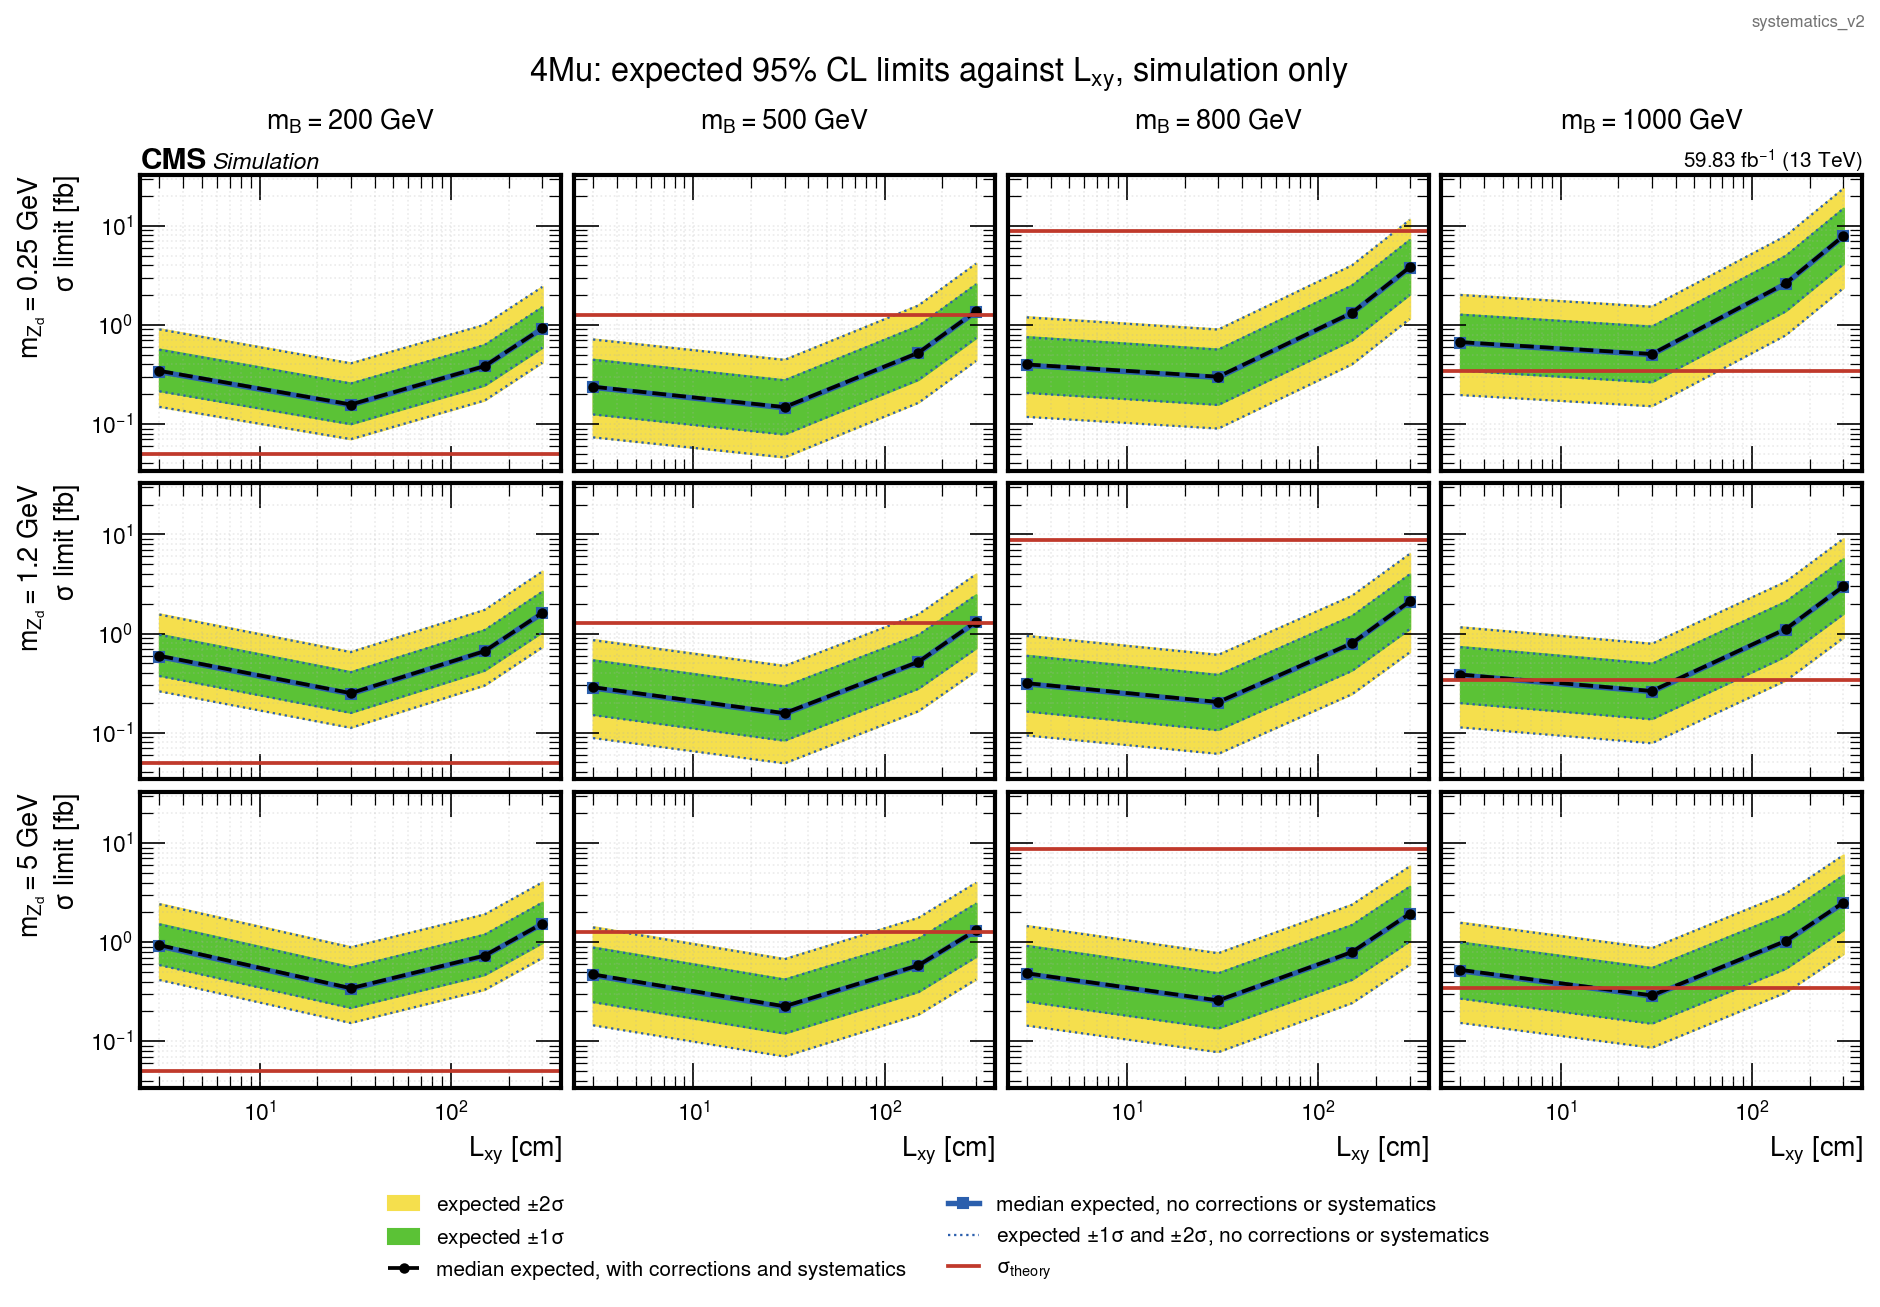

2Mu2E: median expected limit with / without corrections and systematics: median 1.020, from 0.974 to 1.046 (48 points)
4Mu: median expected limit with / without corrections and systematics: median 1.013, from 1.006 to 1.020 (48 points)


In [5]:
FIGURES = WORK / "figures"
for final_state in ("2Mu2E", "4Mu"):
    for against, what in (("m_bound", "bound state mass"), ("lxy", "$L_{xy}$")):
        path = pt.brazil_grid(rows["with"], final_state, FIGURES, CAMPAIGN, against=against,
                              overlay=rows["without"], overlay_label=SETS["without"]["label"],
                              label_median=f"median expected, {SETS['with']['label']}",
                              title=f"{final_state}: expected 95% CL limits against {what}, simulation only",
                              name=f"limits_vs_{against}_{final_state}")
        display(Image(filename=str(path.with_suffix(".png"))))
sysstudy.upload(FIGURES, f"{OUTPUT_DIR}/figures")

without = {r["signal"]: r["exp"] for r in rows["without"]}
for final_state in ("2Mu2E", "4Mu"):
    ratio = np.array([r["exp"] / without[r["signal"]] for r in rows["with"]
                      if r["fs"] == final_state and r["signal"] in without])
    if len(ratio):
        print(f"{final_state}: median expected limit with / without corrections and systematics: median "
              f"{np.median(ratio):.3f}, from {ratio.min():.3f} to {ratio.max():.3f} ({len(ratio)} points)")

**Interpretation.** The two sets differ by a few percent at most: with the corrections and
systematics the limits are a median 2.0% higher for 2Mu2E (from 2.6% lower to 4.6% higher) and
1.3% higher for 4Mu (0.6 to 2.0%), too little to see on these logarithmic axes. Almost all of it
is the corrections, which lower the signal efficiency; the systematics alone move the limits by
at most 0.3% (notebook 04). Both sets exclude the same points: 12 of 48 for 2Mu2E (all twelve at
800 GeV) and 23 of 48 for 4Mu (all twelve at 800 GeV, nine at 500 GeV and two at 1000 GeV).

The shapes follow the signal acceptance and the model:
* Against $L_{xy}$ the limits are best at 30 cm in every panel and weaken towards 3 and 300 cm.
  At 300 cm the generator-filter efficiency adds to this: it is a median 0.55 (2Mu2E) and 0.57
  (4Mu) there, against 0.80 and 0.83 at 3 and 30 cm.
* The 4Mu limits are stronger than the 2Mu2E ones at every point, a median 10 times (best 0.15
  against 0.70 fb), since the predicted 4mu background is below one event.
* The model cross section peaks at 800 GeV and is small at 200 and 1000 GeV, so the exclusion
  sits at 800 GeV, and for 4Mu also at 500 GeV (except at 300 cm) and at two 1000 GeV points.

Against the same limits on `systematics_v1`, which lacked the generator-filter efficiency, every
limit is higher by exactly the inverse of its point's efficiency (0.36 to 0.90 on the limit
grid): a median 1.38 times for 2Mu2E and 1.32 times for 4Mu, from 1.12 to 2.77 times. That
costs one excluded point in 2Mu2E (500 GeV, $m_{Z_d}$ = 0.25 GeV, 30 cm) and four in 4Mu (the
three 500 GeV points at 300 cm, and 1000 GeV, 1.2 GeV, 3 cm).

**For the analysis:** the corrections cost about 2% of sensitivity and the basic systematics
none that matters. The generator-filter efficiency is a normalisation, not an uncertainty: the
v10 samples store only the events that pass the generator filter, so without it every signal
yield was too high by the inverse of the efficiency. The exclusion pattern is set by the model
cross section and the signal acceptance, and the 2Mu2E numbers carry the caveat on the
simulated background in section 1.

## 5. Nuisance pulls

The pulls of the constrained nuisances in the fit of one point's card with the corrections and
systematics (`sidm/scripts/run_combine_pulls.py`): Combine's `FitDiagnostics` on the
expected background-only (Asimov) dataset, as a blinded analysis does, in the
background-only and the signal-plus-background fit. Each marker is the fitted value
relative to the pre-fit one, in units of the pre-fit uncertainty, with the post-fit
uncertainty as its error bar: on the Asimov dataset the pulls are zero by construction, and
an error bar shorter than one would mean the fit constrains that nuisance beyond its
pre-fit uncertainty. The free background parameters of the ABCD model are not shown, since
they have no pre-fit constraint.

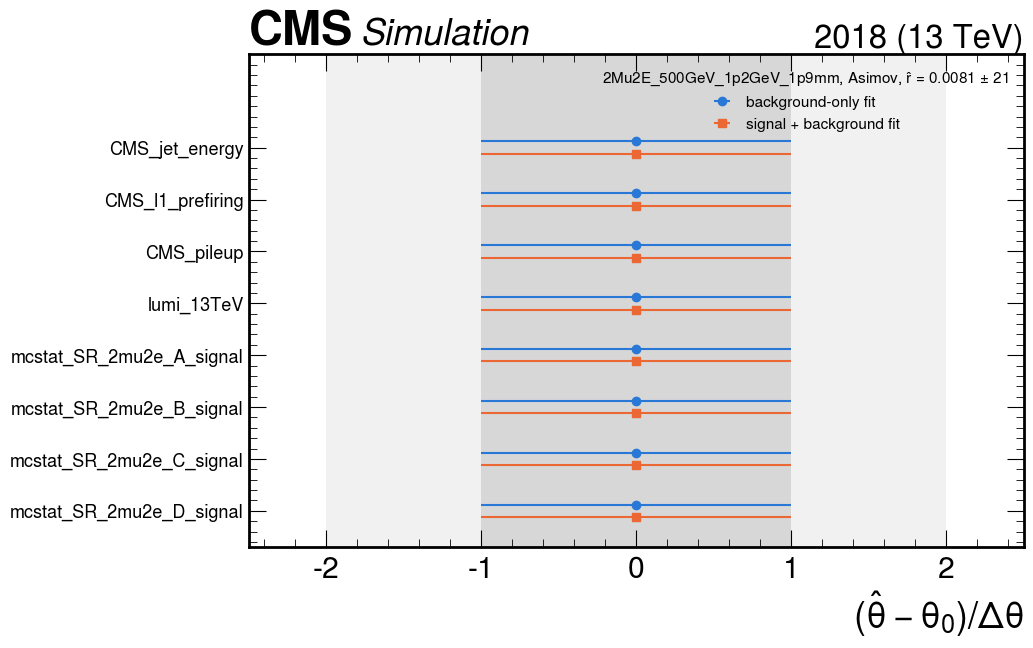

fit status (0 is success): {'fit_b': 0, 'fit_s': 0}


In [6]:
channel, point = PULLS_POINT
card = WORK / "cards_with" / f"datacard_shape_{channel}_{point}.txt"
sysstudy.run_script("run_combine_pulls.py", card, "--outdir", WORK / f"pulls_{point}",
                    combine=COMBINE, log=WORK / f"pulls_{point}.log")
sysstudy.upload(WORK, OUTPUT_DIR)
with fsspec.open(f"{OUTPUT_DIR}/pulls_{point}/pulls.json") as f:
    pulls = json.load(f)
names = sorted(pulls["nuisances"], key=lambda n: (n.startswith("mcstat"), n))

fig, ax = plt.subplots(figsize=(10, 2 + 0.55 * len(names)))
y = np.arange(len(names))[::-1]
for band, alpha in ((2, 0.12), (1, 0.25)):
    ax.axvspan(-band, band, color=GRAY, alpha=alpha, lw=0)
for fit, offset, color, marker, label in (("fit_b", 0.12, BLUE, "o", "background-only fit"),
                                          ("fit_s", -0.12, ORANGE, "s", "signal + background fit")):
    pull = [(pulls["nuisances"][n][fit][0] - pulls["nuisances"][n]["prefit"][0]) / pulls["nuisances"][n]["prefit"][1]
            for n in names]
    error = [pulls["nuisances"][n][fit][1] / pulls["nuisances"][n]["prefit"][1] for n in names]
    ax.errorbar(pull, y + offset, xerr=error, fmt=marker, color=color, ms=6, label=label)
ax.set_yticks(y)
ax.set_yticklabels(names, fontsize=13)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-0.7, len(names) + 0.8)    # room for the legend above the first row
ax.set_xlabel(r"$(\hat\theta - \theta_0)/\Delta\theta$")
r_fit = pulls["r"].get("fit_s", [float("nan")] * 2)
ax.legend(title=f"{point}, Asimov, $\\hat r$ = {r_fit[0]:.2g} $\\pm$ {r_fit[1]:.2g}", fontsize=11,
          title_fontsize=11, loc="upper right")
study.cms_label(ax)
plt.show()
print("fit status (0 is success):", pulls["status"])

**Interpretation.** Every nuisance sits at zero with its full pre-fit uncertainty in both fits.
That is expected and is not a problem: the constrained nuisances of these cards all act on the
signal alone, so a fit without signal carries no information on them, and with the signal
floating they cannot be told apart from $r$. The ±21 on $\hat r$ is not an uncertainty: $r$ is
kept at or above 0, the fit to a background-only dataset lands on that boundary, and there the
fitter's parabolic error means nothing.

**For the analysis:** this plot shows nothing new until nuisances on the background enter, for
example the agreed 20% per-bin uncertainty of the region-A prediction. What each systematic does
to $r$ is in the impacts of notebook 04.

Everything is on EOS now, so the local working directory goes.

In [7]:
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v2_limits


## Adding a systematic

1. Add an entry to `systematics.yaml`: `flat` for a fixed value, `syst` for a correction
   whose up and down weight categories the campaign stored, or `variant` for a histogram
   filled with a varied input (as `abcd6d_*_iso_up` is for the jet energy).
2. If it needs new histograms or weight variations, add them to `hists.py` or
   `corrections.yaml` and rerun the campaign.
3. Rerun this notebook, and describe the new source in `README.md`.